TEST 1 t-test: t=1.094, p=0.2738
         count    mean
Group                 
Mon-Fri  29736  310.27
Sunday    4619  294.39 

TEST 2 ANOVA: F=6.583, p=0.0001917
Quarter
Q1    307.45
Q2    291.26
Q3    313.37
Q4    315.67
Name: Value, dtype: float64 

TEST 3 Chi-square: chi2=35.79, dof=5, p=1.048e-06, Cramer's V=0.079
Market           Non-UK    UK
Segment                      
At Risk              44   774
Champions           117  1313
Lost                137  1334
Loyal Customers     102  1083
Need Attention       46   328
New / Promising      64   380


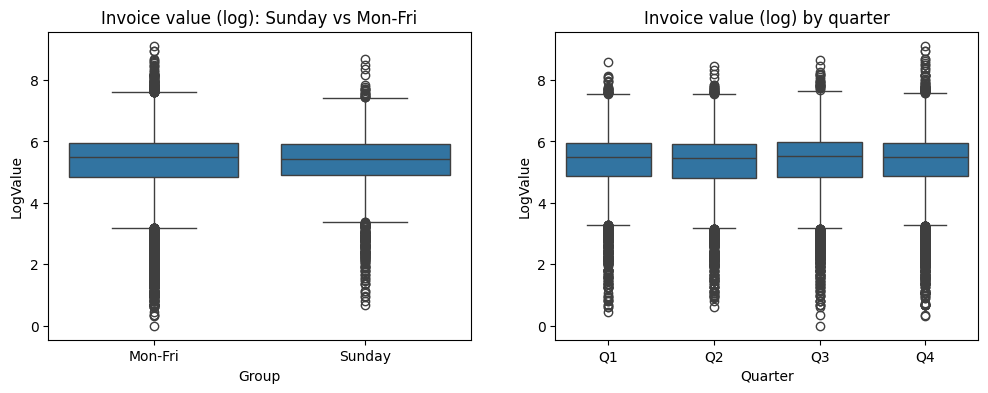

In [1]:
import pandas as pd, numpy as np, os
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
os.makedirs("figures", exist_ok=True)

df = pd.read_csv("../Task2_EDA_Cleaning/data/cleaned_retail.csv", parse_dates=["InvoiceDate"])
rfm = pd.read_csv("../Task3_RFM_Dashboard/rfm_customers.csv")

# One row per invoice
inv = df.groupby('Invoice').agg(InvoiceDate=('InvoiceDate','first'), Value=('Revenue','sum')).reset_index()
inv['LogValue'] = np.log1p(inv['Value'])          # log fixes the skew
inv['Weekday'] = inv['InvoiceDate'].dt.day_name()
inv['Group'] = np.where(inv['Weekday']=='Sunday', 'Sunday', 'Mon-Fri')
inv['Quarter'] = 'Q' + inv['InvoiceDate'].dt.quarter.astype(str)

# ---- TEST 1: Welch t-test, Sunday vs weekday invoice value ----
a = inv.loc[inv.Group=='Sunday','LogValue']; b = inv.loc[inv.Group=='Mon-Fri','LogValue']
t, p1 = stats.ttest_ind(a, b, equal_var=False)
print("TEST 1 t-test: t=%.3f, p=%.4g" % (t, p1))
print(inv.groupby('Group')['Value'].agg(['count','mean']).round(2), "\n")

# ---- TEST 2: ANOVA, invoice value across quarters ----
F, p2 = stats.f_oneway(*[g['LogValue'] for _, g in inv.groupby('Quarter')])
print("TEST 2 ANOVA: F=%.3f, p=%.4g" % (F, p2))
print(inv.groupby('Quarter')['Value'].mean().round(2), "\n")

# ---- TEST 3: Chi-square, segment vs market (UK / non-UK) ----
rfm['Market'] = np.where(rfm['Country']=='United Kingdom', 'UK', 'Non-UK')
ct = pd.crosstab(rfm['Segment'], rfm['Market'])
chi2, p3, dof, _ = stats.chi2_contingency(ct)
cramer = np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape)-1)))
print("TEST 3 Chi-square: chi2=%.2f, dof=%d, p=%.4g, Cramer's V=%.3f" % (chi2, dof, p3, cramer))
print(ct)

# ---- Plots for the report ----
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=inv, x='Group', y='LogValue', ax=ax[0]); ax[0].set_title("Invoice value (log): Sunday vs Mon-Fri")
sns.boxplot(data=inv, x='Quarter', y='LogValue', order=['Q1','Q2','Q3','Q4'], ax=ax[1]); ax[1].set_title("Invoice value (log) by quarter")
plt.savefig("figures/1_hypothesis_tests.png", dpi=150, bbox_inches="tight"); plt.show()

Multiple Comparison of Means - Tukey HSD, FWER=0.05 
group1 group2 meandiff p-adj   lower   upper  reject
----------------------------------------------------
    Q1     Q2  -0.0592 0.0028 -0.1028 -0.0156   True
    Q1     Q3  -0.0126 0.8777 -0.0557  0.0306  False
    Q1     Q4   0.0018 0.9995  -0.038  0.0416  False
    Q2     Q3   0.0466 0.0189  0.0055  0.0878   True
    Q2     Q4    0.061 0.0002  0.0234  0.0985   True
    Q3     Q4   0.0143 0.7524 -0.0227  0.0514  False
----------------------------------------------------
24 months
Best model: SARIMA(0, 0, 1) x (0, 0, 0, 12), AIC=474.0
SARIMA         RMSE=191214  MAPE=26.2%
Seasonal-naive RMSE=41705  MAPE=6.8%
Test months inside the 95% interval: 5 of 6
          Forecast  Lower 95%  Upper 95%
Dec 2011  582876.0   326627.0   839125.0
Jan 2012  439194.0   151867.0   726521.0
Feb 2012  439194.0   151867.0   726521.0


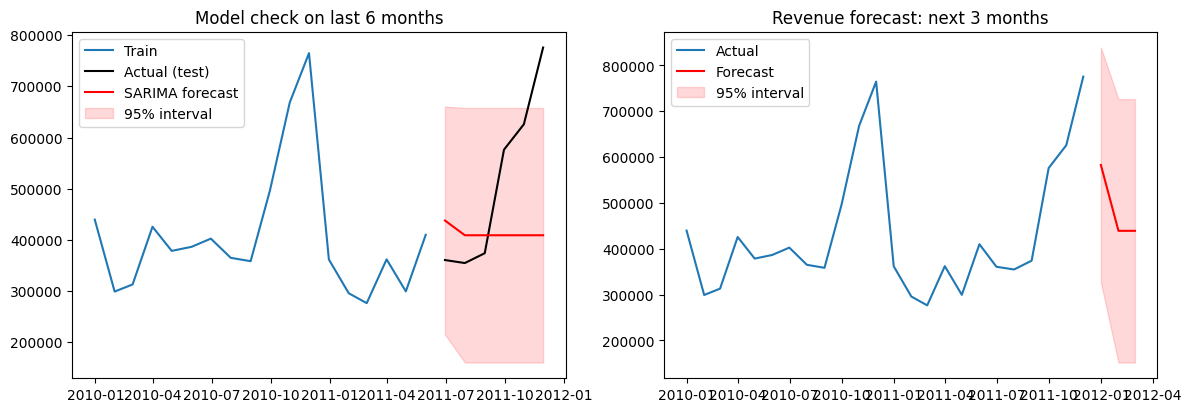

In [2]:
import itertools, warnings
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.stats.multicomp import pairwise_tukeyhsd
warnings.filterwarnings("ignore")

# ---- Post-hoc: which quarters differ? ----
print(pairwise_tukeyhsd(inv['LogValue'], inv['Quarter']).summary())

# ---- Monthly revenue (drop incomplete Dec 2011) ----
monthly = df.set_index('InvoiceDate')['Revenue'].resample('ME').sum()
monthly = monthly[:'2011-11-30']
print(len(monthly), "months")
train, test = monthly[:-6], monthly[-6:]

# ---- Pick best SARIMA by AIC ----
best = None
for p, q, P in itertools.product([0,1], [0,1], [0,1]):
    try:
        m = SARIMAX(train, order=(p,0,q), seasonal_order=(P,0,0,12), trend='c').fit(disp=False)
        if best is None or m.aic < best[0]:
            best = (m.aic, (p,0,q), (P,0,0,12), m)
    except Exception:
        pass
aic, order, sorder, model = best
print("Best model: SARIMA%s x %s, AIC=%.1f" % (order, sorder, aic))

# ---- Test on last 6 months ----
fc = model.get_forecast(steps=6)
pred, ci = fc.predicted_mean, fc.conf_int(alpha=0.05)
naive = monthly.shift(12)[-6:]          # same month last year (baseline)

def rmse(a, b): return float(np.sqrt(np.mean((a.values - b.values)**2)))
def mape(a, b): return float(np.mean(np.abs((a.values - b.values) / a.values)) * 100)
print("SARIMA         RMSE=%.0f  MAPE=%.1f%%" % (rmse(test, pred), mape(test, pred)))
print("Seasonal-naive RMSE=%.0f  MAPE=%.1f%%" % (rmse(test, naive), mape(test, naive)))
inside = ((test.values >= ci.iloc[:,0].values) & (test.values <= ci.iloc[:,1].values)).sum()
print("Test months inside the 95%% interval: %d of 6" % inside)

# ---- Refit on all data and forecast 3 months ----
final = SARIMAX(monthly, order=order, seasonal_order=sorder, trend='c').fit(disp=False)
f3 = final.get_forecast(steps=3)
ci3 = f3.conf_int(alpha=0.05)
tbl = pd.DataFrame({"Forecast": f3.predicted_mean, "Lower 95%": ci3.iloc[:,0], "Upper 95%": ci3.iloc[:,1]}).round(0)
tbl.index = tbl.index.strftime('%b %Y')
print(tbl)

# ---- Plots ----
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ax[0].plot(train.index, train, label="Train")
ax[0].plot(test.index, test, label="Actual (test)", color="black")
ax[0].plot(pred.index, pred, label="SARIMA forecast", color="red")
ax[0].fill_between(ci.index, ci.iloc[:,0], ci.iloc[:,1], color="red", alpha=.15, label="95% interval")
ax[0].set_title("Model check on last 6 months"); ax[0].legend()
ax[1].plot(monthly.index, monthly, label="Actual")
ax[1].plot(f3.predicted_mean.index, f3.predicted_mean, color="red", label="Forecast")
ax[1].fill_between(ci3.index, ci3.iloc[:,0], ci3.iloc[:,1], color="red", alpha=.15, label="95% interval")
ax[1].set_title("Revenue forecast: next 3 months"); ax[1].legend()
plt.savefig("figures/2_forecast.png", dpi=150, bbox_inches="tight"); plt.show()

                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       3.583e+05   1.75e+04     20.446      0.000    3.21e+05    3.95e+05
Peak        2.847e+05   4.29e+04      6.632      0.000    1.94e+05    3.76e+05
R-squared: 0.73
                               RMSE  MAPE %
SARIMA                     191214.1    26.2
Seasonal regression         61402.9     6.2
Seasonal naive (baseline)   41705.0     6.8
Test months inside the 95% interval (regression): 6 of 6
          Forecast  Lower 95%  Upper 95%
Dec 2011  359153.0   218455.0   499851.0
Jan 2012  359153.0   218455.0   499851.0
Feb 2012  359153.0   218455.0   499851.0


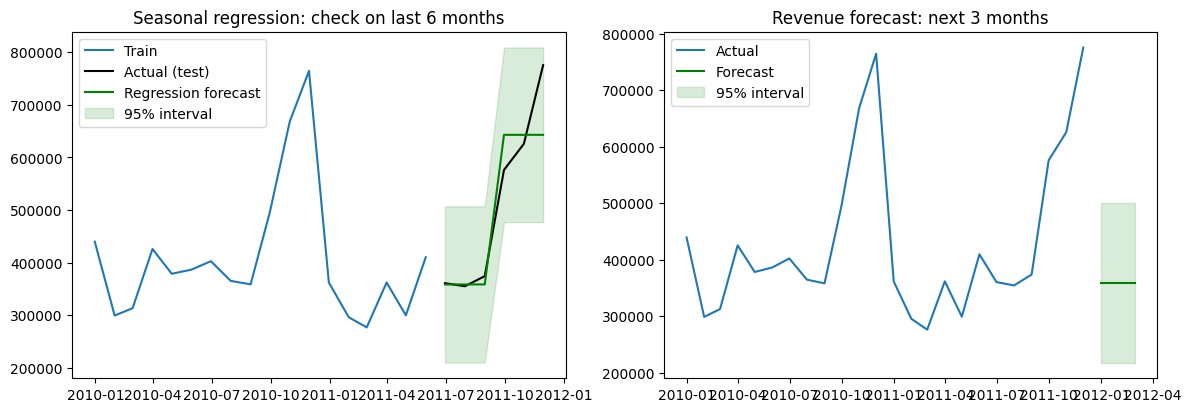

In [3]:
import statsmodels.api as sm

def make_X(idx):
    X = pd.DataFrame({'Peak': idx.month.isin([9, 10, 11]).astype(int)}, index=idx)
    return sm.add_constant(X, has_constant='add')

reg = sm.OLS(train, make_X(train.index)).fit()
print(reg.summary().tables[1])
print("R-squared: %.2f" % reg.rsquared)

sf = reg.get_prediction(make_X(test.index)).summary_frame(alpha=0.05)
reg_pred = sf['mean']
inside_r = ((test.values >= sf['obs_ci_lower'].values) & (test.values <= sf['obs_ci_upper'].values)).sum()

results = pd.DataFrame({
    "RMSE": [rmse(test, pred), rmse(test, reg_pred), rmse(test, naive)],
    "MAPE %": [mape(test, pred), mape(test, reg_pred), mape(test, naive)]},
    index=["SARIMA", "Seasonal regression", "Seasonal naive (baseline)"]).round(1)
print(results)
print("Test months inside the 95%% interval (regression): %d of 6" % inside_r)

full = sm.OLS(monthly, make_X(monthly.index)).fit()
fut_idx = pd.date_range(monthly.index[-1] + pd.offsets.MonthEnd(1), periods=3, freq='ME')
sf3 = full.get_prediction(make_X(fut_idx)).summary_frame(alpha=0.05)
tbl = sf3[['mean', 'obs_ci_lower', 'obs_ci_upper']].round(0)
tbl.columns = ["Forecast", "Lower 95%", "Upper 95%"]
tbl.index = fut_idx.strftime('%b %Y')
print(tbl)

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ax[0].plot(train.index, train, label="Train")
ax[0].plot(test.index, test, label="Actual (test)", color="black")
ax[0].plot(reg_pred.index, reg_pred, label="Regression forecast", color="green")
ax[0].fill_between(sf.index, sf['obs_ci_lower'], sf['obs_ci_upper'], color="green", alpha=.15, label="95% interval")
ax[0].set_title("Seasonal regression: check on last 6 months"); ax[0].legend()
ax[1].plot(monthly.index, monthly, label="Actual")
ax[1].plot(fut_idx, sf3['mean'], color="green", label="Forecast")
ax[1].fill_between(fut_idx, sf3['obs_ci_lower'], sf3['obs_ci_upper'], color="green", alpha=.15, label="95% interval")
ax[1].set_title("Revenue forecast: next 3 months"); ax[1].legend()
plt.savefig("figures/3_regression_forecast.png", dpi=150, bbox_inches="tight"); plt.show()